# Phase 1: Exploratory Data Analysis (EDA)
## Telco Customer Churn Prediction

### Executive Summary & Objectives
The goal of this phase is to conduct a thorough exploratory analysis of the Telco Customer Churn dataset to uncover the primary factors driving customer attrition, evaluate data quality, identify risks such as data leakage, and establish clear preprocessing requirements for model development in Phase 2.

**Dataset:** `data/Telco-Customer-Churn.csv`  
**Target Variable:** `Churn` (`'Yes'` / `'No'`)


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Required libraries imported successfully.")

Required libraries imported successfully.


---
## 1. Data Ingestion & Initial Inspection

We load the dataset from `data/Telco-Customer-Churn.csv` and inspect its shape, column types, and sample records.


In [2]:
# Resolve dataset path dynamically whether executed from root or notebooks directory
data_path = os.path.join('..', 'data', 'Telco-Customer-Churn.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'Telco-Customer-Churn.csv')

df = pd.read_csv(data_path)
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Dimensions: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Inspect data schema and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

---
## 2. Data Hygiene & Integrity Checks

We examine:
1. **Duplicate records** across all columns or unique identifiers.
2. **Explicit and implicit missing values** (such as empty whitespace strings).
3. **Data type inconsistencies** (specifically `TotalCharges` stored as an `object`).


In [4]:
# Check for duplicate rows and customer IDs
total_duplicates = df.duplicated().sum()
id_duplicates = df['customerID'].duplicated().sum()

print(f"Duplicate full records: {total_duplicates}")
print(f"Duplicate customerID entries: {id_duplicates}")

Duplicate full records: 0
Duplicate customerID entries: 0


In [5]:
# Check explicit nulls vs implicit whitespace
print("Explicit NaN count per column:")
print(df.isnull().sum())

# Inspect TotalCharges whitespace strings
whitespace_mask = df['TotalCharges'].astype(str).str.strip() == ''
num_whitespace = whitespace_mask.sum()
print(f"\nImplicit missing values in 'TotalCharges' (empty whitespace ' '): {num_whitespace}")

# Examine customers with whitespace TotalCharges
sample_whitespace = df[whitespace_mask][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']]
sample_whitespace

Explicit NaN count per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Implicit missing values in 'TotalCharges' (empty whitespace ' '): 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


> **Diagnostic Finding on Missing Values:**
> - All 11 records with whitespace `TotalCharges` correspond exactly to customers with `tenure == 0`.
> - These are brand new accounts that signed up during the current billing cycle and have not yet been issued their first monthly invoice.
> - **Imputation Strategy:** Coerce `TotalCharges` to float and fill missing values with `0.0`.


In [6]:
# Create clean exploratory working dataframe
eda_df = df.copy()
eda_df['TotalCharges'] = pd.to_numeric(eda_df['TotalCharges'], errors='coerce')
eda_df['TotalCharges'] = eda_df['TotalCharges'].fillna(0.0)

print(f"TotalCharges nulls after coercion & imputation: {eda_df['TotalCharges'].isnull().sum()}")
print(f"TotalCharges new dtype: {eda_df['TotalCharges'].dtype}")

TotalCharges nulls after coercion & imputation: 0
TotalCharges new dtype: float64


---
## 3. Target Variable Analysis: Churn Distribution & Class Imbalance

Understanding the class distribution is crucial for setting expectations around accuracy, choosing appropriate scoring metrics (e.g., ROC-AUC, PR-AUC, Recall), and planning the cross-validation strategy.


Target Class Breakdown:
  No: 5174 (73.46%)
  Yes: 1869 (26.54%)


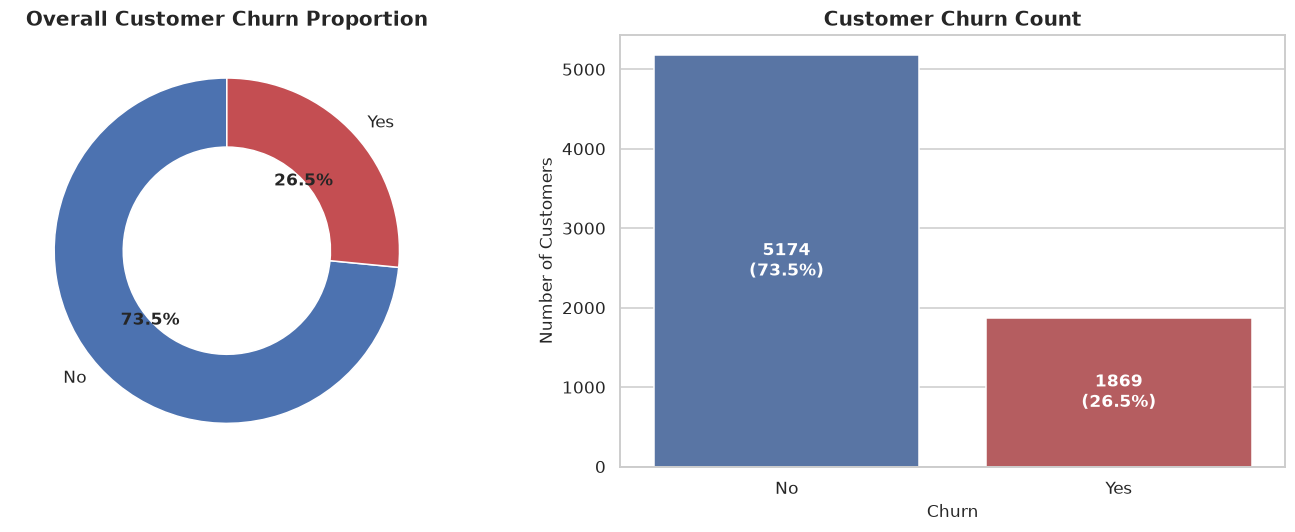

In [7]:
churn_counts = eda_df['Churn'].value_counts()
churn_pcts = eda_df['Churn'].value_counts(normalize=True) * 100

print("Target Class Breakdown:")
for label, count in churn_counts.items():
    print(f"  {label}: {count} ({churn_pcts[label]:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
palette = ['#4C72B0', '#C44E52']

# Donut chart
wedges, texts, autotexts = axes[0].pie(
    churn_counts, 
    labels=churn_counts.index, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=palette, 
    wedgeprops=dict(width=0.4, edgecolor='w')
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_weight('bold')
axes[0].set_title('Overall Customer Churn Proportion', fontweight='bold')

# Bar plot with count and percentage annotations
sns.countplot(x='Churn', data=eda_df, ax=axes[1], palette=palette)
axes[1].set_title('Customer Churn Count', fontweight='bold')
axes[1].set_ylabel('Number of Customers')
for p in axes[1].patches:
    height = p.get_height()
    pct = (height / len(eda_df)) * 100
    axes[1].annotate(f'{int(height)}\n({pct:.1f}%)',
                     (p.get_x() + p.get_width() / 2., height / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

> **Implications of Class Imbalance:**
> - **Imbalance Ratio:** ~73.5% Retained (`'No'`) vs ~26.5% Churned (`'Yes'`) (approx 2.77:1).
> - **Metric Caveat:** Raw accuracy is misleading; a dummy baseline predicting `'No'` yields 73.5% accuracy but zero business utility.
> - **Modeling Requirements:** We must prioritize **Recall** (capturing maximum churners), **PR-AUC**, **ROC-AUC**, and use **Stratified K-Fold** cross-validation.


---
## 4. Numerical Features Analysis

We evaluate the three continuous numerical features: `tenure`, `MonthlyCharges`, and `TotalCharges`.


In [8]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
display_summary = eda_df.groupby('Churn')[num_cols].agg(['mean', 'median', 'std', 'min', 'max'])
display_summary.T

Churn                           No          Yes
tenure         mean      37.569965    17.979133
               median    38.000000    10.000000
               std       24.113777    19.531123
               min        0.000000     1.000000
               max       72.000000    72.000000
MonthlyCharges mean      61.265124    74.441332
               median    64.425000    79.650000
               std       31.092648    24.666053
               min       18.250000    18.850000
               max      118.750000   118.350000
TotalCharges   mean    2549.911442  1531.796094
               median  1679.525000   703.550000
               std     2329.954215  1890.822994
               min        0.000000    18.850000
               max     8672.450000  8684.800000

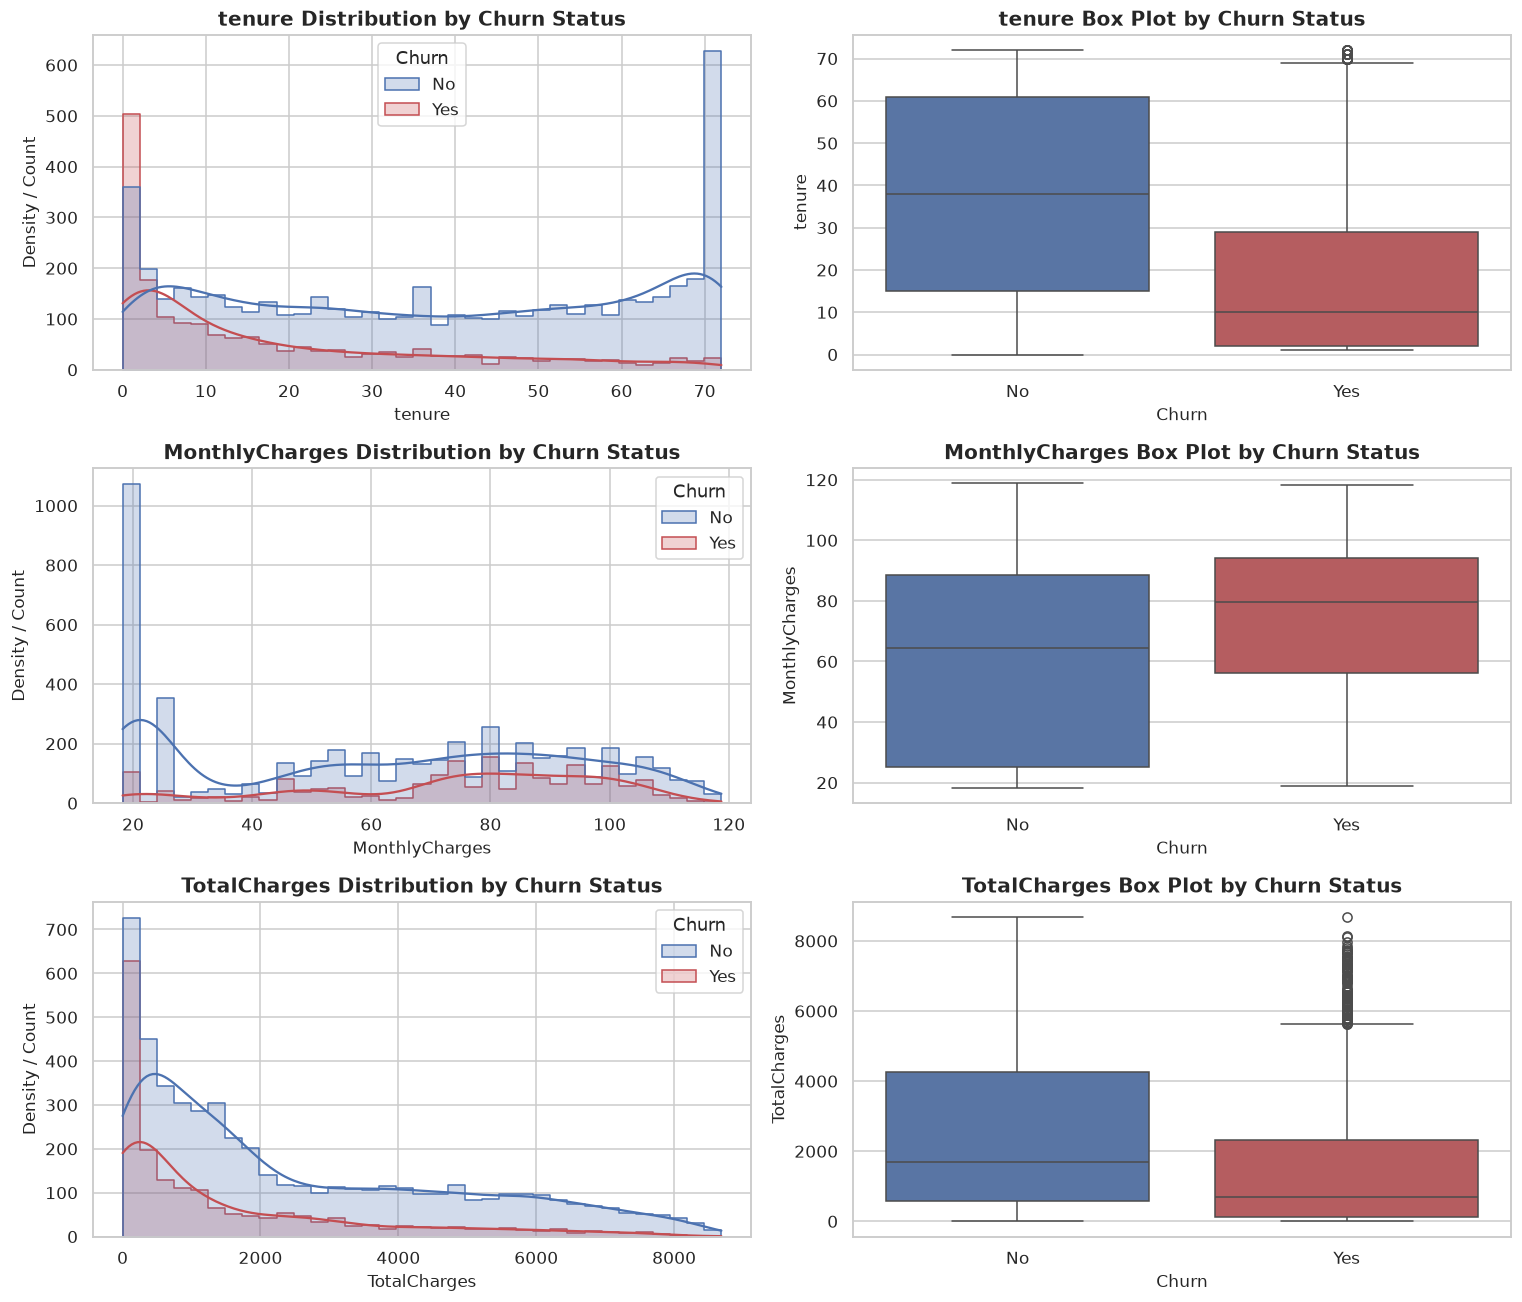

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
palette_map = {'No': '#4C72B0', 'Yes': '#C44E52'}

for i, col in enumerate(num_cols):
    # Distribution / KDE plot
    sns.histplot(data=eda_df, x=col, hue='Churn', kde=True, ax=axes[i, 0],
                 palette=palette_map, element='step', common_norm=False, bins=35)
    axes[i, 0].set_title(f'{col} Distribution by Churn Status', fontweight='bold')
    axes[i, 0].set_ylabel('Density / Count')
    
    # Box plot
    sns.boxplot(data=eda_df, x='Churn', y=col, ax=axes[i, 1], palette=palette_map)
    axes[i, 1].set_title(f'{col} Box Plot by Churn Status', fontweight='bold')

plt.tight_layout()
plt.show()

> **Key Numerical Insights:**
> 1. **Tenure (Onboarding Cliff):**
>    - Churned customers have a median tenure of only **10 months**, compared to **38 months** for loyal customers.
>    - The churn risk is overwhelmingly concentrated in months 1 to 6. Once a customer passes month 24, attrition decreases sharply.
> 2. **Monthly Charges:**
>    - Churned customers pay significantly higher monthly rates (median **$79.65** vs **$64.43** for non-churners).
>    - High pricing creates immediate churn pressure, especially when unbundled or lacking technical support.
> 3. **Total Charges:**
>    - TotalCharges is lower for churners (median **$701.50** vs **$1,683.60**) purely because of their short tenure.


---
## 5. Categorical Features Analysis

We evaluate how churn rates vary across customer subgroups:
1. **Demographics:** Gender, Senior Citizen, Partner, Dependents
2. **Account & Contract Terms:** Contract, Paperless Billing, Payment Method
3. **Subscribed Services:** Internet Service, Tech Support, Security, Streaming, etc.


In [10]:
def plot_categorical_churn(features, title, ncols=2):
    nrows = (len(features) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.2 * nrows))
    axes = axes.flatten() if (nrows > 1 or ncols > 1) else [axes]
    
    for idx, feat in enumerate(features):
        ax = axes[idx]
        df_group = eda_df.groupby(feat)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).reset_index()
        df_counts = eda_df.groupby(feat)['Churn'].count().reset_index().rename(columns={'Churn': 'TotalCount'})
        merged = pd.merge(df_group, df_counts, on=feat)
        
        bars = sns.barplot(data=merged, x=feat, y='Churn', ax=ax, palette='Blues_r')
        ax.set_title(f'Churn Rate by {feat}', fontweight='bold')
        ax.set_ylabel('Churn Rate (%)')
        ax.set_ylim(0, 65)
        ax.axhline(churn_pcts['Yes'], color='red', linestyle='--', linewidth=1.2, label=f'Avg ({churn_pcts["Yes"]:.1f}%)')
        
        for p, count in zip(ax.patches, merged['TotalCount']):
            h = p.get_height()
            ax.annotate(f'{h:.1f}%\n(n={count})',
                        (p.get_x() + p.get_width() / 2., h + 1.2),
                        ha='center', va='bottom', fontsize=9.5)
        ax.legend(loc='upper right')
        
    for j in range(len(features), len(axes)):
        fig.delaxes(axes[j])
        
    plt.suptitle(title, fontsize=15, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

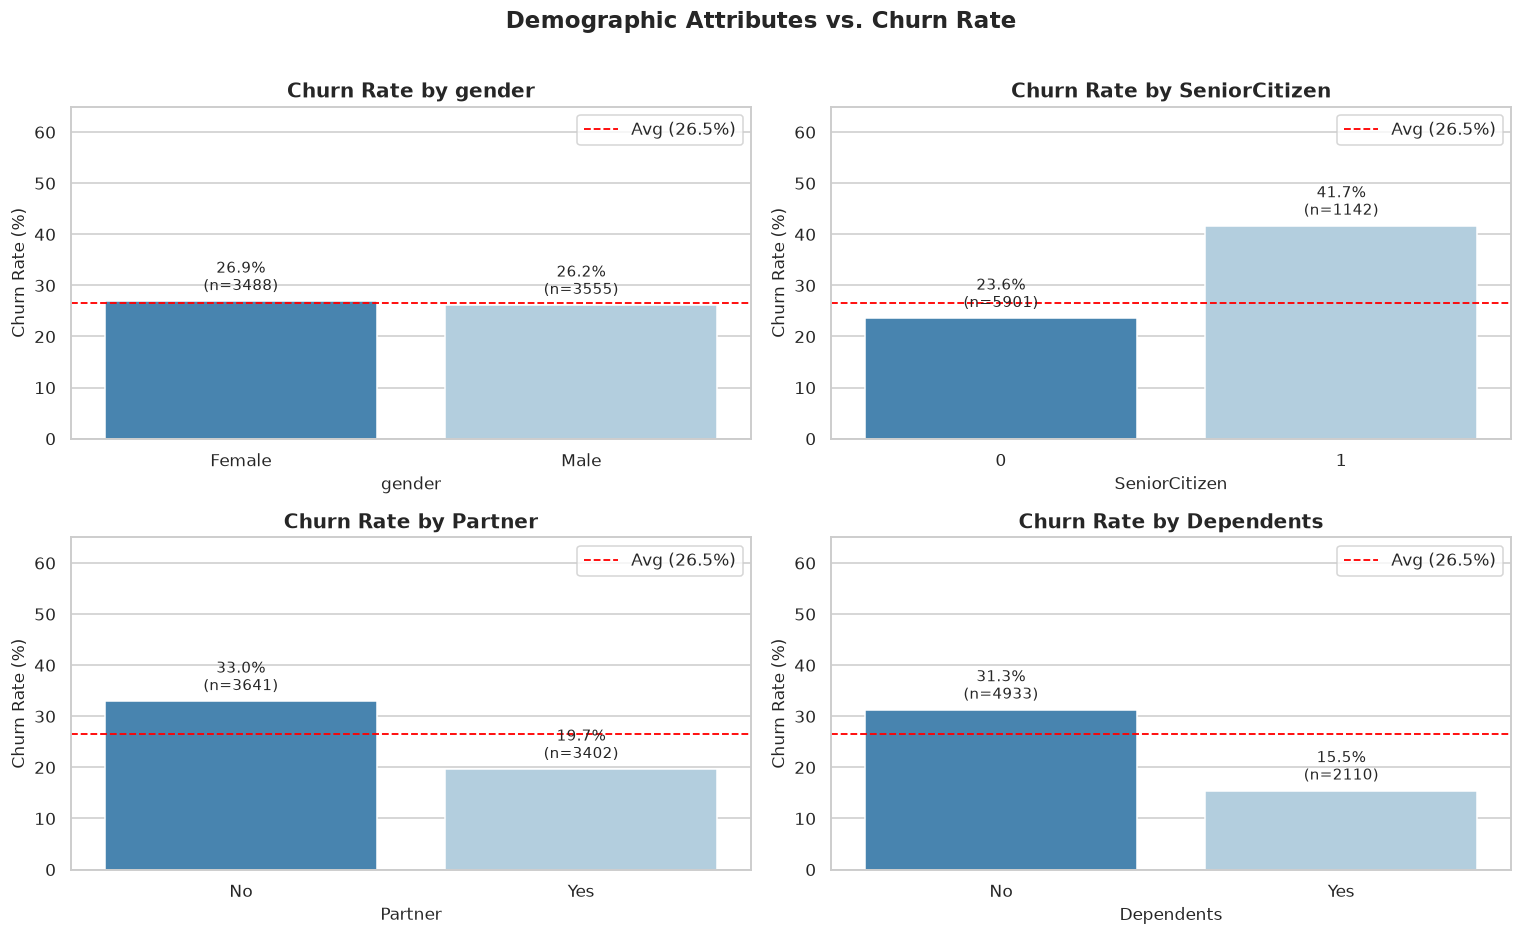

In [11]:
# 5.1 Demographics
demographics = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']
plot_categorical_churn(demographics, 'Demographic Attributes vs. Churn Rate')

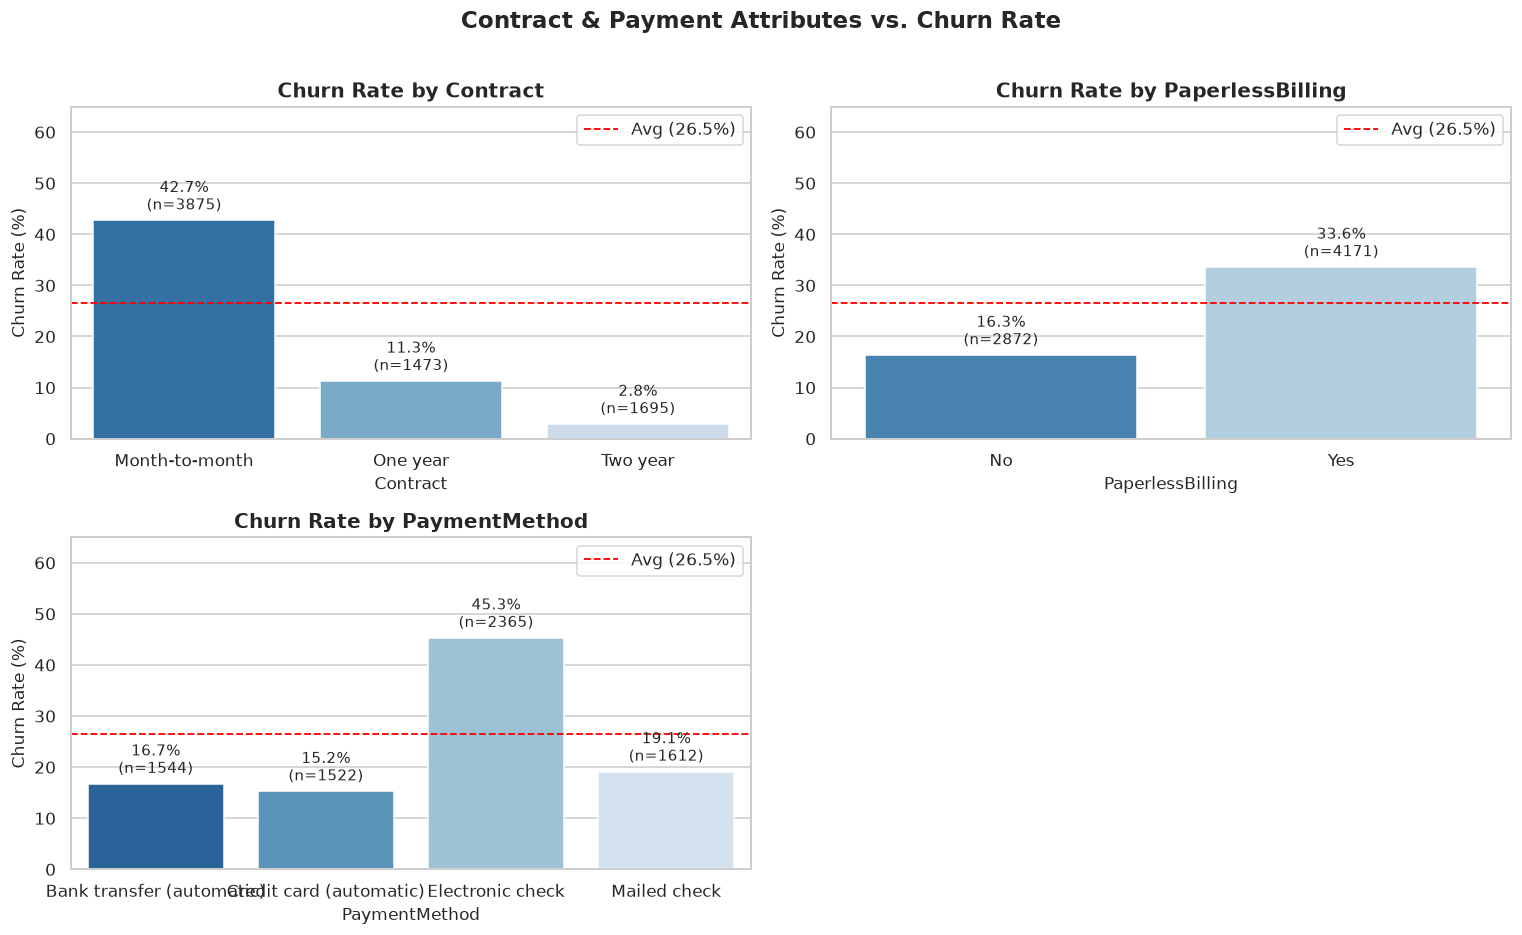

In [12]:
# 5.2 Account & Contract Architecture
contracts = ['Contract', 'PaperlessBilling', 'PaymentMethod']
plot_categorical_churn(contracts, 'Contract & Payment Attributes vs. Churn Rate')

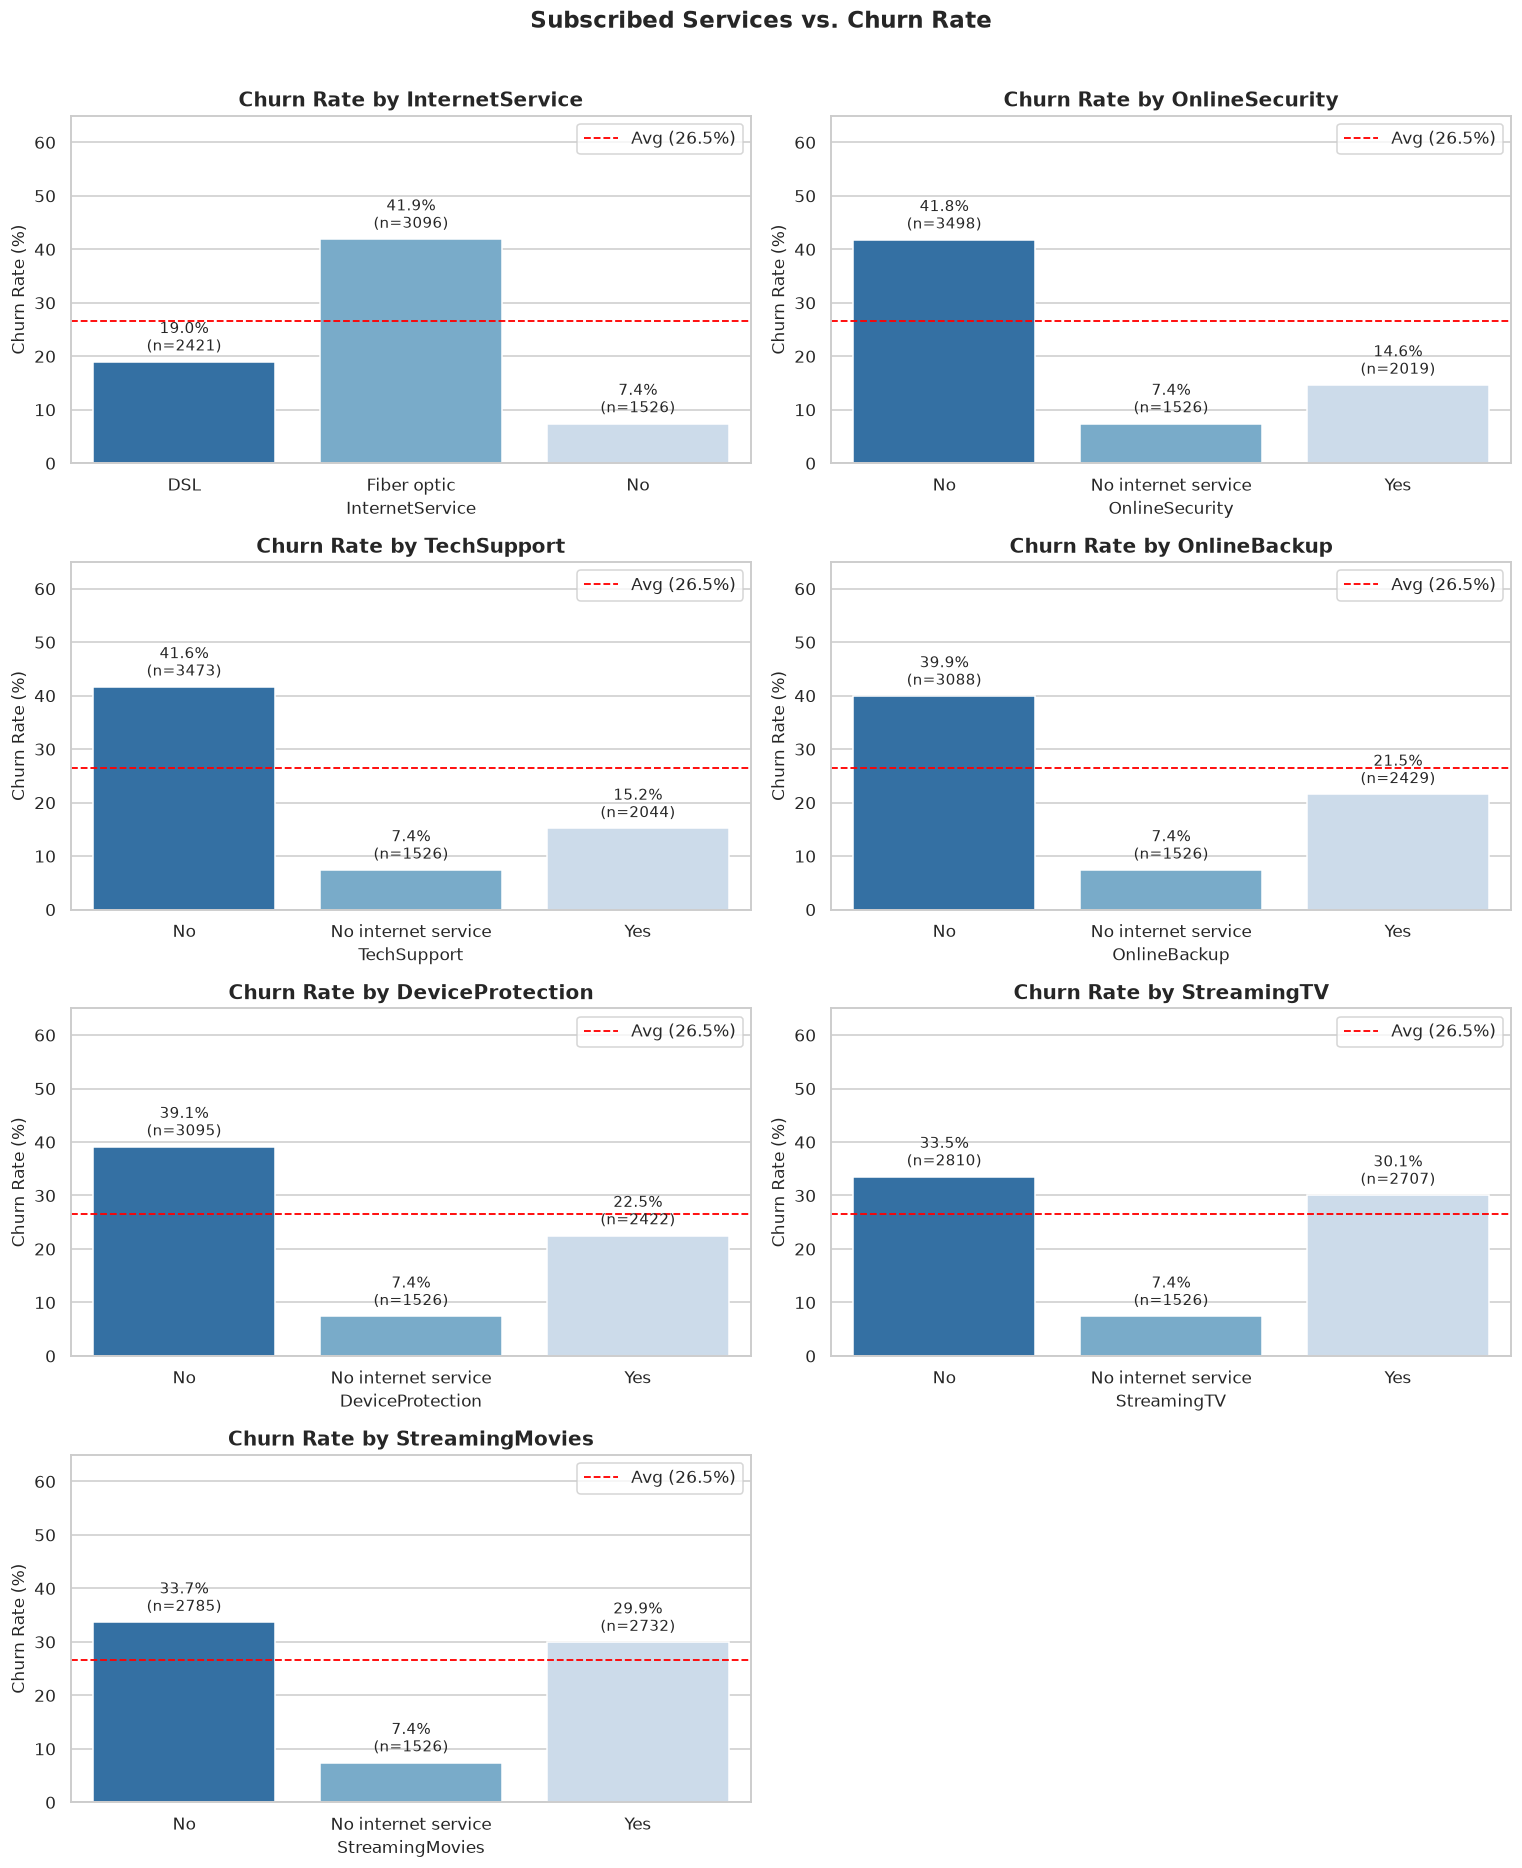

In [13]:
# 5.3 Service Subscriptions
services = ['InternetService', 'OnlineSecurity', 'TechSupport', 'OnlineBackup', 'DeviceProtection', 'StreamingTV', 'StreamingMovies']
plot_categorical_churn(services, 'Subscribed Services vs. Churn Rate', ncols=2)

> **Categorical Drivers Summary:**
> 1. **Contract Type is the single strongest behavioral predictor:**
>    - Month-to-month contracts have a **42.7% churn rate**.
>    - One-year contracts drop to **11.3%**, and two-year contracts plummet to **2.8%**.
> 2. **Internet Service & Tech Ecosystem:**
>    - **Fiber Optic** customers churn at **41.9%** (vs **19.0%** for DSL and **7.4%** for No Internet). Fiber optic plans have higher monthly charges and higher expectations.
>    - Customers without **TechSupport** (41.6%) and without **OnlineSecurity** (41.8%) churn at double the company baseline. Value-added support acts as a retention moat.
> 3. **Payment Method & Billing:**
>    - **Electronic check** users exhibit a **45.3% churn rate**, compared to **15.2% – 18.2%** for automated credit card and bank transfer methods.
> 4. **Demographics:**
>    - Gender shows negligible difference (~26.2% male vs ~26.9% female).
>    - Senior citizens churn at **41.7%** (vs 23.6% for non-seniors). Customers with partners/dependents are substantially stickier.


---
## 6. Correlation & Multicollinearity Analysis

We assess numerical correlations and dummy variable associations with churn.


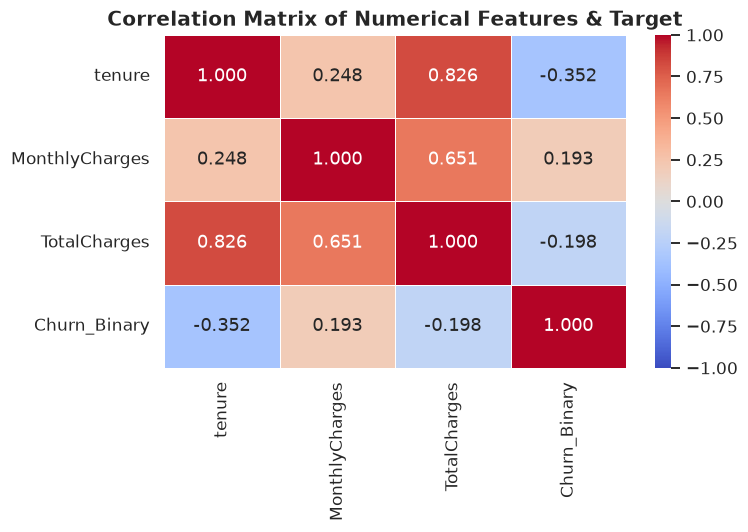

In [14]:
# 6.1 Numerical Correlations
eda_df['Churn_Binary'] = (eda_df['Churn'] == 'Yes').astype(int)
num_corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_Binary']
corr_matrix = eda_df[num_corr_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.3f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features & Target', fontweight='bold')
plt.tight_layout()
plt.show()

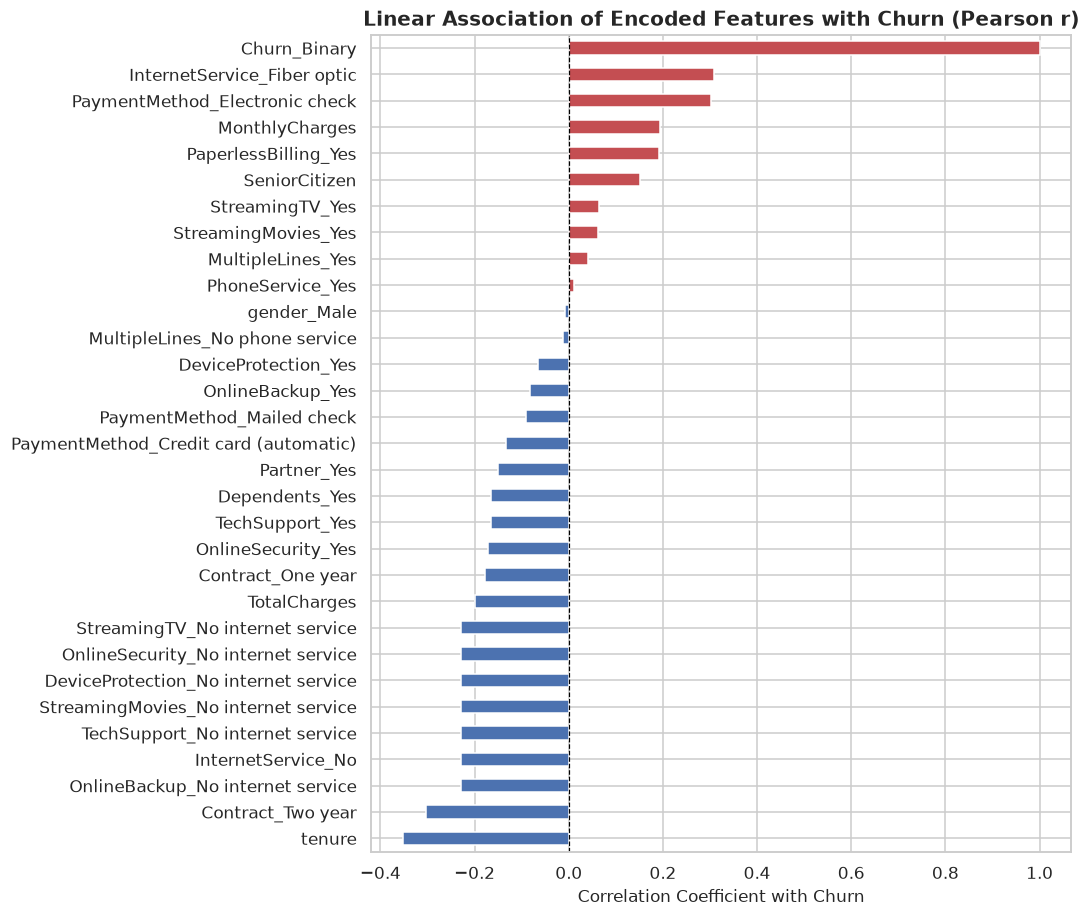

In [15]:
# 6.2 Full Feature Association Ranking with Churn
encoded_df = pd.get_dummies(eda_df.drop(columns=['customerID', 'Churn']), drop_first=True, dtype=int)
correlations_with_churn = encoded_df.apply(lambda col: col.corr(eda_df['Churn_Binary'])).sort_values()

plt.figure(figsize=(10, 8.5))
bar_colors = ['#4C72B0' if val < 0 else '#C44E52' for val in correlations_with_churn]
correlations_with_churn.plot(kind='barh', color=bar_colors)
plt.title('Linear Association of Encoded Features with Churn (Pearson r)', fontweight='bold')
plt.xlabel('Correlation Coefficient with Churn')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.tight_layout()
plt.show()

> **Multicollinearity & Association Insights:**
> - **High Multicollinearity:** `tenure` and `TotalCharges` exhibit strong positive correlation ($r = 0.826$), which is structurally expected since `TotalCharges ≈ tenure * MonthlyCharges`. Linear models will need regularization (L2 Ridge / ElasticNet) or tree ensembles that tolerate collinearity.
> - **Top Protective Features:** Long tenure, Two-year contract, One-year contract, No internet service, Online Security, Tech Support.
> - **Top Churn Risk Features:** Month-to-month contract, Fiber optic internet, Electronic check payment, Paperless billing, High monthly charges.


---
## 7. Data Leakage Assessment & Preprocessing Requirements

### 7.1 Data Leakage Risks
1. **`customerID` Column:**
   - Must be dropped from model input features ($X$). It is a purely unique administrative identifier with 7,043 distinct values; including it would lead to arbitrary memorization and zero generalizability.
2. **Target Leakage:**
   - None observed in the raw feature set (all features reflect subscriber attributes observable prior to churn event).
3. **Preprocessing Leakage Prevention:**
   - All scalers (`StandardScaler`), imputers, and encoders (`OneHotEncoder`) must be fit strictly on the **training split** and applied to the test/validation splits to prevent data snooping.

### 7.2 Preprocessing Requirements for Phase 2 Pipeline
1. **Missing Value Imputation:**
   - For records where `tenure == 0` (11 rows), impute `TotalCharges = 0.0` or `TotalCharges = MonthlyCharges * tenure`.
2. **Target Encoding:**
   - Map `Churn`: `'Yes' -> 1`, `'No' -> 0`.
3. **Categorical Feature Encoding:**
   - Use `OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')` on multi-class features.
4. **Feature Scaling:**
   - Apply `StandardScaler` to continuous features (`tenure`, `MonthlyCharges`, `TotalCharges`) for regularized linear models (Logistic Regression) and distance-based estimators.
5. **Validation Strategy:**
   - Use **Stratified K-Fold** cross-validation ($k=5$) to preserve the 26.5% minority class ratio across all splits.


In [16]:
# Summary Verification of Pipeline Parameters
print("=== PREPROCESSING CONFIGURATION SUMMARY ===")
print(f"1. Target variable: 'Churn' (Distribution: {churn_pcts['Yes']:.2f}% positive)")
print(f"2. ID feature to drop: 'customerID'")
print(f"3. Numerical features to scale: {num_cols}")
print(f"4. Missing TotalCharges rows handled: {num_whitespace} rows (tenure == 0)")
cat_cols = [c for c in df.columns if c not in num_cols + ['customerID', 'Churn']]
print(f"5. Categorical features to encode ({len(cat_cols)}): {cat_cols}")

=== PREPROCESSING CONFIGURATION SUMMARY ===
1. Target variable: 'Churn' (Distribution: 26.54% positive)
2. ID feature to drop: 'customerID'
3. Numerical features to scale: ['tenure', 'MonthlyCharges', 'TotalCharges']
4. Missing TotalCharges rows handled: 11 rows (tenure == 0)
5. Categorical features to encode (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


---
## 8. Summary of Findings & Next Steps

### Key Empirical Findings
- **Overall Churn Rate:** 26.54% (1,869 / 7,043).
- **Core Churn Driver:** Contract term (Month-to-month contracts churn at 42.7% vs 2.8% for 2-year contracts).
- **Onboarding Risk Window:** Highest attrition happens in the first 1–6 months of customer tenure.
- **Service Vulnerabilities:** Fiber optic subscribers churn at 41.9%, and customers without tech support or online security are twice as likely to churn.
- **Payment Friction:** Electronic check payment method is associated with a 45.3% churn rate.

### Deliverables Transition to Phase 2 (Modeling)
1. Build reusable `src/data_loader.py` and `src/preprocessor.py` adhering to the specifications established here.
2. Train and benchmark candidate algorithms:
   - Logistic Regression (interpretable baseline)
   - Random Forest Classifier
   - Gradient Boosting (LightGBM / XGBoost)
3. Evaluate using ROC-AUC, PR-AUC, Recall, Precision, and Confusion Matrices.
4. Compute SHAP values for global and local customer risk explainability.
